# 7. Optimización de hiperparámetros

Cuatro métodos, el mismo espacio y el mismo presupuesto (16 configuraciones por búsqueda, cada una
evaluada con 3 pliegues internos), dentro de la validación anidada del capítulo 6. Toda métrica
de desempeño de este capítulo viene del **bucle externo**, salvo cuando se dice explícitamente
que es el puntaje interno (el que guía la búsqueda).

In [1]:
import sys, json, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from osha_e3 import config as C, models as M, nested as N, analysis as A, plots as P, search as S, cache
P.setup()
OPTS = ['grid', 'random', 'bayes', 'genetic']
fc, fr = N.fold_table('clf'), N.fold_table('reg')
mc, mr = N.master_table('clf'), N.master_table('reg')
print('Celdas de clasificación:', len(fc), '| de regresión:', len(fr))
print('Evaluaciones por celda (mín., máx.):', fc.n_evals.min(), fc.n_evals.max(), fr.n_evals.min(), fr.n_evals.max())

Celdas de clasificación: 560 | de regresión: 140
Evaluaciones por celda (mín., máx.): 16 16 16 16


## 7.1 Los cuatro métodos

**Grid Search.** Recorre una rejilla fija de 16 puntos dentro del espacio (tabla 6.6). Es
exhaustiva en la rejilla pero ciega fuera de ella: si el óptimo cae entre dos valores, no lo ve, y
con varios hiperparámetros la rejilla solo puede probar 2 valores de cada uno.

**Random Search.** 16 puntos uniformes en el espacio codificado (escala log incluida). Con el
mismo número de puntos prueba 16 valores distintos de *cada* hiperparámetro, lo que ayuda
cuando solo unos pocos importan (Bergstra y Bengio, 2012).

**Optimización bayesiana (Optuna).**
- *Modelo sustituto:* **Tree-structured Parzen Estimator (TPE)**. Separa las configuraciones ya
  evaluadas en «buenas» (cuantil superior γ del puntaje) y «malas», y estima con núcleos de Parzen
  las densidades l(x) = p(x | bueno) y g(x) = p(x | malo). Se usa la versión multivariada, que
  modela los hiperparámetros conjuntamente.
- *Función de adquisición:* **Mejora Esperada (EI)**. En TPE, maximizar EI equivale a elegir el
  candidato con mayor razón l(x)/g(x) entre 24 candidatos muestreados de l(x).
- *Exploración-explotación:* las 5 primeras configuraciones son aleatorias (exploración pura); luego
  TPE explota las regiones con alta l/g, pero como los candidatos se muestrean de l(x) (una
  mezcla de núcleos con ancho finito) sigue explorando alrededor. EI favorece más la explotación
  que UCB con κ grande; con solo 16 evaluaciones es una elección razonable.

**Algoritmo genético (DEAP).** Cada individuo es un vector de genes en [0, 1] (uno por
hiperparámetro), decodificado igual que en Random Search.
- *Selección:* torneo de tamaño 3: presión moderada, insensible a la escala del puntaje (solo
  importa el orden), a diferencia de la ruleta.
- *Cruce:* mezcla BLX-α (α = 0,5) con probabilidad 0,8: los hijos pueden caer algo fuera del
  segmento entre los padres, lo que mantiene exploración en genes reales.
- *Mutación:* gaussiana (σ = 0,15 en la escala [0, 1], probabilidad por gen 0,5), aplicada al 30 %
  de los hijos.
- *Elitismo y población:* 6 individuos; el mejor pasa intacto a la siguiente generación. Con 16
  evaluaciones, una población pequeña es la única forma de tener varias generaciones (6 iniciales +
  2 generaciones de 5 hijos); una población grande sería solo una búsqueda aleatoria.
- Las configuraciones repetidas no se reevalúan ni consumen presupuesto.

## 7.2 Desempeño externo por método

In [2]:
def summary(f, metric, higher=True):
    g = f.groupby('optimizer')
    out = pd.DataFrame({
        f'{metric} externo (media de celdas)': g[f'outer_{metric}'].mean(),
        'tiempo de búsqueda total (h·núcleo)': g.search_seconds.sum() / 3600,
        'tiempo medio por evaluación (s)': g.eval_seconds_mean.mean(),
        'evaluaciones totales': g.n_evals.sum(),
        'ajustes totales (× 3 pliegues internos)': g.n_evals.sum() * C.INNER_FOLDS,
    }).reindex(OPTS)
    return out
print('Clasificación (balanced accuracy externa):')
display(summary(fc, 'recall').round(4))
print('Regresión (RMSE externo, log1p días):')
display(summary(fr, 'rmse').round(4))

Clasificación (balanced accuracy externa):


,recall externo (media de celdas),tiempo de búsqueda total (h·núcleo),tiempo medio por evaluación (s),evaluaciones totales,ajustes totales (× 3 pliegues internos)
optimizer,,,,,
grid,0.3990,12.0105,18.2235,2240,6720
random,0.3975,12.5903,19.1369,2240,6720
bayes,0.4023,14.0720,21.3581,2240,6720
genetic,0.3968,11.9859,17.9859,2240,6720


Regresión (RMSE externo, log1p días):


,rmse externo (media de celdas),tiempo de búsqueda total (h·núcleo),tiempo medio por evaluación (s),evaluaciones totales,ajustes totales (× 3 pliegues internos)
optimizer,,,,,
grid,1.3705,0.8472,5.4263,560,1680
random,1.3709,0.7662,4.9061,560,1680
bayes,1.3708,0.7847,5.0160,560,1680
genetic,1.3706,0.7040,4.5052,560,1680


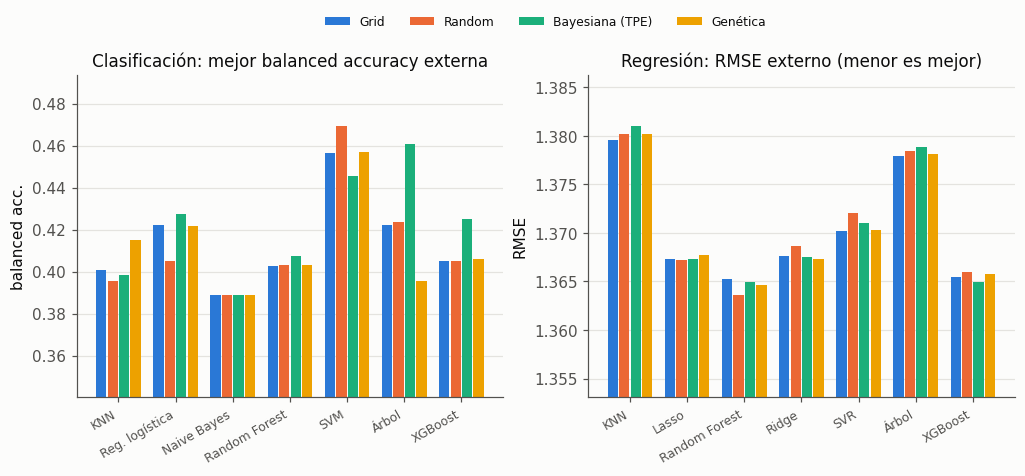

In [3]:
pv = mc.pivot_table(index='model', columns='optimizer', values='outer_recall_mean', aggfunc='max').reindex(columns=OPTS)
pv.index = [M.PRETTY[i] for i in pv.index]
pr = mr.pivot_table(index='model', columns='optimizer', values='outer_rmse_mean', aggfunc='min').reindex(columns=OPTS)
pr.index = [M.PRETTY[i] for i in pr.index]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, tab, title, lab in [(axes[0], pv, 'Clasificación: mejor balanced accuracy externa', 'balanced acc.'),
                            (axes[1], pr, 'Regresión: RMSE externo (menor es mejor)', 'RMSE')]:
    x = np.arange(len(tab)); w = 0.2
    for j, o in enumerate(OPTS):
        ax.bar(x + (j - 1.5) * w, tab[o], width=w - 0.02, color=P.OPT_COLORS[o], label=M.PRETTY[o])
    ax.set_xticks(x, tab.index, rotation=30, ha='right', fontsize=8); ax.set_title(title); ax.set_ylabel(lab)
    lo = np.nanmin(tab.to_numpy()); hi = np.nanmax(tab.to_numpy()); ax.set_ylim(lo - (hi - lo) * 0.6, hi + (hi - lo) * 0.3)
    ax.grid(axis='x', visible=False)
axes[0].legend(ncol=4, fontsize=8, loc='upper center', bbox_to_anchor=(1.1, 1.22))
P.save(fig, 'e3_hpo_por_modelo'); plt.show()

**Interpretación.** Con el mismo presupuesto (16 configuraciones), los cuatro métodos llegan a modelos de calidad casi igual
en el bucle externo: la balanced accuracy media de sus 140 celdas va de 0,397 (genético) a 0,402
(bayesiano), y el RMSE de regresión difiere en la cuarta cifra decimal (1,3705 a 1,3709). Por modelo, las
diferencias grandes aparecen solo donde la métrica depende de Fallecimiento (árbol: 0,461 con TPE frente a
0,395 con el genético; SVM: 0,469 con Random frente a 0,445 con TPE), es decir, donde el ruido de esa clase
domina. En costo, la búsqueda bayesiana gastó un 17 % más de tiempo (14,1 frente a ~12 horas·núcleo en
clasificación) porque explora más las zonas caras del espacio (más árboles, más vecinos); en regresión el
genético fue el más barato. En total, la validación anidada consumió unas 51 horas·núcleo en clasificación
y 3,1 en regresión, con 8.960 y 2.240 configuraciones evaluadas (26.880 y 6.720 ajustes).

## 7.3 Convergencia: curvas de desempeño en cualquier momento (*anytime*)

Para cada celda se toma el mejor puntaje **interno** encontrado hasta la evaluación t. Para poder
promediar entre modelos con escalas distintas se normaliza dentro de cada (modelo, balanceo,
pliegue externo): 0 es el peor puntaje que obtuvo cualquier método y 1 el mejor. En Grid Search
la curva depende del orden en que se recorre la rejilla (aquí, el orden de `ParameterGrid`).

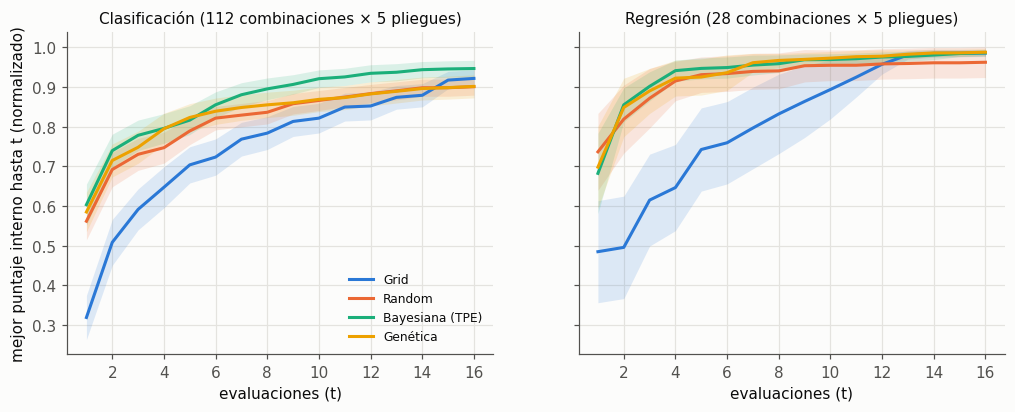

In [4]:
any_c, any_r = A.anytime_table('clf'), A.anytime_table('reg')
eff_c, full_c = A.budget_efficiency(any_c)
eff_r, full_r = A.budget_efficiency(any_r)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, full, title in [(axes[0], full_c, 'Clasificación (112 combinaciones × 5 pliegues)'),
                        (axes[1], full_r, 'Regresión (28 combinaciones × 5 pliegues)')]:
    for o in OPTS:
        x = full.xs(o, level='optimizer')
        m = x.mean(); se = x.std() / np.sqrt(len(x))
        ax.plot(m.index, m.values, color=P.OPT_COLORS[o], label=M.PRETTY[o])
        ax.fill_between(m.index, m - 1.96 * se, m + 1.96 * se, color=P.OPT_COLORS[o], alpha=0.15, lw=0)
    ax.set_xlabel('evaluaciones (t)'); ax.set_title(title, fontsize=10)
axes[0].set_ylabel('mejor puntaje interno hasta t (normalizado)')
axes[0].legend(fontsize=8, loc='lower right')
P.save(fig, 'e3_hpo_anytime'); plt.show()

In [5]:
print('Clasificación'); display(eff_c.reindex(OPTS).round(3))
print('Regresión'); display(eff_r.reindex(OPTS).round(3))

Clasificación


,celdas,AUC anytime (0-1),calidad con 4 evals,calidad con 8 evals,calidad con 12 evals,calidad con 16 evals,evals para 99 % del final (mediana)
optimizer,,,,,,,
grid,140,0.749,0.648,0.784,0.852,0.922,9.0
random,140,0.818,0.747,0.837,0.884,0.901,7.0
bayes,140,0.864,0.796,0.896,0.935,0.947,7.0
genetic,140,0.830,0.795,0.855,0.883,0.902,9.0


Regresión


,celdas,AUC anytime (0-1),calidad con 4 evals,calidad con 8 evals,calidad con 12 evals,calidad con 16 evals,evals para 99 % del final (mediana)
optimizer,,,,,,,
grid,35,0.810,0.647,0.832,0.958,0.986,9.0
random,35,0.922,0.915,0.941,0.958,0.963,6.0
bayes,35,0.938,0.941,0.959,0.976,0.986,7.0
genetic,35,0.937,0.923,0.967,0.978,0.988,8.0


## 7.4 Evidencia cuantitativa: calidad por unidad de presupuesto

La comparación visual no basta. Para cada celda (modelo × balanceo × pliegue externo) se calcula
el área bajo la curva anytime normalizada (promedio de la curva en t = 1…16; 1 sería encontrar
el mejor puntaje en la primera evaluación). Las celdas son pareadas (mismos datos para los cuatro
métodos), así que se comparan con Friedman y luego con Wilcoxon de rangos con signo por pares,
con corrección de Holm. También se compara la calidad alcanzada **a mitad de presupuesto
(t = 8)** y el puntaje externo final.

In [6]:
from osha_e3 import stats_tests as T
def budget_tests(full, f, metric, higher):
    auc = A.paired_auc(full)[OPTS]
    half = full[8].unstack('optimizer')[OPTS].dropna()
    fr_auc = T.friedman(auc.to_numpy())
    outer = f.pivot_table(index=['model', 'balance', 'fold'], columns='optimizer', values=f'outer_{metric}')[OPTS].dropna()
    rows = []
    for a, b in [('bayes', 'grid'), ('bayes', 'random'), ('genetic', 'grid'), ('genetic', 'random'), ('bayes', 'genetic'), ('random', 'grid')]:
        for label, tab, sign in [('AUC anytime', auc, 1), ('calidad en t=8', half, 1), (f'{metric} externo', outer, 1 if higher else -1)]:
            d = (tab[a] - tab[b]) * sign
            p = stats.wilcoxon(tab[a], tab[b]).pvalue if (d != 0).any() else 1.0
            rows.append({'comparación': f'{M.PRETTY[a]} vs {M.PRETTY[b]}', 'medida': label, 'diferencia media (a − b, + = a mejor)': d.mean(),
                         'a gana en (% celdas)': (d > 0).mean() * 100, 'p Wilcoxon': p,
                         'delta de Cliff': T.cliffs_delta(tab[a] * sign, tab[b] * sign)})
    out = pd.DataFrame(rows)
    for m_ in out['medida'].unique():
        idx = out['medida'] == m_
        out.loc[idx, 'p ajustado (Holm)'] = T.adjust(out.loc[idx, 'p Wilcoxon'].to_numpy())
    return fr_auc, out
fr_c, bt_c = budget_tests(full_c, fc, 'recall', True)
fr_r, bt_r = budget_tests(full_r, fr, 'rmse', False)
print(f"Friedman sobre el AUC anytime — clasificación: chi2 = {fr_c['chi2']:.1f}, p = {fr_c['p_value']:.2g}; "
      f"rangos {dict(zip(OPTS, np.round(fr_c['avg_ranks'], 2)))}")
print(f"Friedman sobre el AUC anytime — regresión: chi2 = {fr_r['chi2']:.1f}, p = {fr_r['p_value']:.2g}; "
      f"rangos {dict(zip(OPTS, np.round(fr_r['avg_ranks'], 2)))}")
bt_c.round(4)

Friedman sobre el AUC anytime — clasificación: chi2 = 50.4, p = 6.5e-11; rangos {'grid': 3.13, 'random': 2.49, 'bayes': 2.11, 'genetic': 2.28}
Friedman sobre el AUC anytime — regresión: chi2 = 24.4, p = 2.1e-05; rangos {'grid': 3.43, 'random': 2.11, 'bayes': 2.26, 'genetic': 2.2}


,comparación,medida,"diferencia media (a − b, + = a mejor)",a gana en (% celdas),p Wilcoxon,delta de Cliff,p ajustado (Holm)
0,Bayesiana (TPE) vs Grid,AUC anytime,0.1156,72.1429,0.0000,0.3876,0.0000
1,Bayesiana (TPE) vs Grid,calidad en t=8,0.1115,63.5714,0.0000,0.2778,0.0000
2,Bayesiana (TPE) vs Grid,recall externo,0.0033,56.4286,0.0616,0.0441,0.3081
3,Bayesiana (TPE) vs Random,AUC anytime,0.0467,66.4286,0.0000,0.2232,0.0001
4,Bayesiana (TPE) vs Random,calidad en t=8,0.0590,67.8571,0.0000,0.2689,0.0000
5,Bayesiana (TPE) vs Random,recall externo,0.0048,56.4286,0.0178,0.0607,0.1069
6,Genética vs Grid,AUC anytime,0.0815,68.5714,0.0000,0.2864,0.0000
7,Genética vs Grid,calidad en t=8,0.0712,60.0000,0.0002,0.1437,0.0009
8,Genética vs Grid,recall externo,-0.0022,55.0000,0.6230,-0.0080,1.0000
9,Genética vs Random,AUC anytime,0.0126,53.5714,0.1163,0.1243,0.2326


In [7]:
bt_r.round(4)

,comparación,medida,"diferencia media (a − b, + = a mejor)",a gana en (% celdas),p Wilcoxon,delta de Cliff,p ajustado (Holm)
0,Bayesiana (TPE) vs Grid,AUC anytime,0.1284,82.8571,0.0000,0.3959,0.0000
1,Bayesiana (TPE) vs Grid,calidad en t=8,0.1266,68.5714,0.0038,0.2310,0.0228
2,Bayesiana (TPE) vs Grid,rmse externo,-0.0003,51.4286,0.4510,-0.0106,1.0000
3,Bayesiana (TPE) vs Random,AUC anytime,0.0157,42.8571,0.8020,-0.0931,1.0000
4,Bayesiana (TPE) vs Random,calidad en t=8,0.0181,60.0000,0.5436,0.0008,1.0000
5,Bayesiana (TPE) vs Random,rmse externo,0.0001,51.4286,0.9806,0.0302,1.0000
6,Genética vs Grid,AUC anytime,0.1273,80.0000,0.0000,0.4351,0.0000
7,Genética vs Grid,calidad en t=8,0.1349,68.5714,0.0045,0.2457,0.0228
8,Genética vs Grid,rmse externo,-0.0001,51.4286,0.7158,-0.0024,1.0000
9,Genética vs Random,AUC anytime,0.0147,48.5714,0.9035,-0.0759,1.0000


**Interpretación.** **Evidencia cuantitativa de eficiencia.** Las pruebas pareadas sobre las 140 celdas de clasificación
confirman lo que muestran las curvas:

- **Friedman** sobre el área bajo la curva *anytime* rechaza que los cuatro métodos sean equivalentes
  (clasificación χ² = 50,4, p = 6,5·10⁻¹¹; regresión χ² = 24,4, p = 2,1·10⁻⁵). Rangos promedio en
  clasificación: bayesiano 2,11 (mejor), genético 2,28, Random 2,49, Grid 3,13.
- **Bayesiano frente a Grid:** +0,116 de área *anytime* (gana en el 72 % de las celdas, Holm p < 0,001,
  δ de Cliff 0,39, mediano) y +0,112 de calidad con la mitad del presupuesto (t = 8).
- **Bayesiano frente a Random:** +0,047 de área (gana en el 66 %, Holm p < 0,001, δ = 0,22, pequeño) y
  +0,059 en t = 8. El TPE alcanza con 8 evaluaciones (0,896) más de lo que Random alcanza con 16 (0,901 en
  la escala normalizada, prácticamente igual) y el 99 % de su valor final en una mediana de 7.
- **Genético frente a Grid:** +0,082 de área (Holm p < 0,001, δ = 0,29). **Genético frente a Random:**
  +0,013, no significativo tras Holm (p = 0,23).
- En regresión el patrón se repite frente a Grid (bayesiano y genético +0,13, δ ≈ 0,40 a 0,44, Holm
  p < 0,001), pero bayesiano, genético y Random quedan empatados (el espacio de Ridge, Lasso y SVR tiene 1 o
  2 dimensiones y cualquier método lo cubre).

**Pero esa eficiencia no se traduce en mejores modelos finales.** En la métrica externa ninguna
diferencia entre métodos es significativa tras Holm (la mayor, bayesiano frente a Random, +0,005 de
balanced accuracy, p crudo 0,018 y ajustado 0,11; δ de Cliff 0,06, despreciable). La explicación es que
el paisaje es plano: muchas configuraciones distintas dan casi el mismo desempeño, así que el método que
encuentra antes la cima solo ahorra presupuesto. La ventaja práctica del bayesiano y del genético es esa:
**llegan al mismo nivel con la mitad de evaluaciones**. Grid es el peor porque su rejilla de 16 puntos
prueba solo 2 valores de cada hiperparámetro en los modelos con 4 o más (XGBoost, Random Forest).

## 7.5 Tiempo de reloj

El presupuesto se fijó en evaluaciones, no en tiempo. El costo por evaluación depende de la
configuración elegida (más árboles o más vecinos cuestan más), así que los métodos que exploran
zonas caras gastan más reloj con el mismo número de evaluaciones.

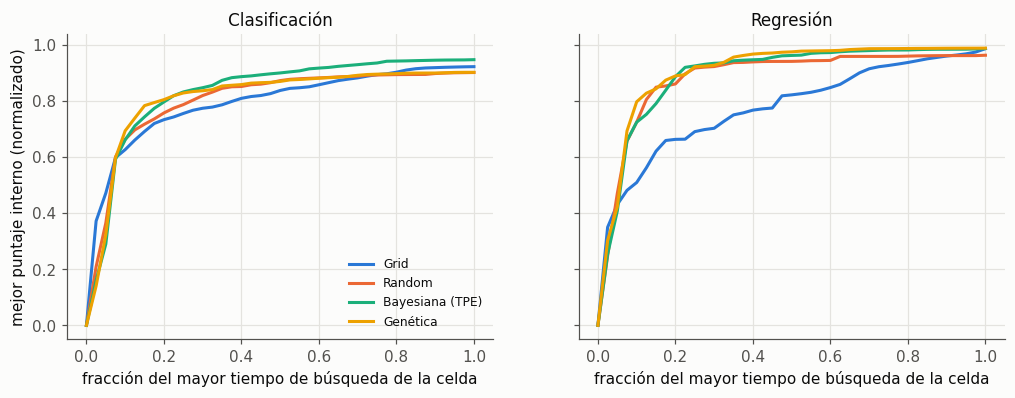

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, anyt, title in [(axes[0], any_c, 'Clasificación'), (axes[1], any_r, 'Regresión')]:
    d = anyt.dropna(subset=['best_norm']).copy()
    d['frac_time'] = d.cum_seconds / d.groupby(['model', 'balance', 'fold']).cum_seconds.transform('max')
    grid_t = np.linspace(0, 1, 41)
    for o in OPTS:
        curves = []
        for _, x in d[d.optimizer == o].groupby(['model', 'balance', 'fold']):
            curves.append(np.interp(grid_t, x.frac_time, x.best_norm, left=0))
        ax.plot(grid_t, np.mean(curves, axis=0), color=P.OPT_COLORS[o], label=M.PRETTY[o])
    ax.set_xlabel('fracción del mayor tiempo de búsqueda de la celda'); ax.set_title(title)
axes[0].set_ylabel('mejor puntaje interno (normalizado)'); axes[0].legend(fontsize=8, loc='lower right')
P.save(fig, 'e3_hpo_anytime_tiempo'); plt.show()

**Interpretación.** En tiempo de reloj el orden se mantiene: el bayesiano alcanza antes su nivel aun gastando más por
evaluación, y Grid sigue siendo el más lento en mejorar. Como el presupuesto se fijó en evaluaciones, un
método que elige configuraciones caras (como hace TPE al explorar muchos árboles) consume más reloj; aun
así su curva queda por encima en casi todo el rango.

## 7.6 Optuna: historia de una búsqueda y superficie explorada

Historia de la búsqueda bayesiana de XGBoost (sin balanceo, pliegue externo 1) y todas las
configuraciones de XGBoost evaluadas por los cuatro métodos en ese pliegue, en el plano
learning rate × profundidad (color = balanced accuracy interna).

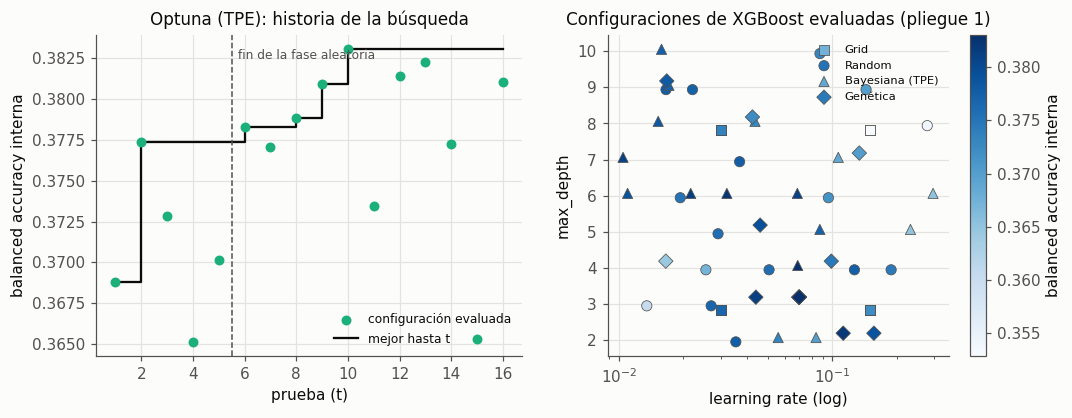

In [9]:
cells = {(r['optimizer']): r for r in N.load_cells('clf') if r['model'] == 'xgboost' and r['balance'] == 'none' and r['fold'] == 0}
h = pd.DataFrame(cells['bayes']['history'])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(h['eval'], h.score, color=P.OPT_COLORS['bayes'], s=30, zorder=3, label='configuración evaluada')
axes[0].step(h['eval'], h.score.cummax(), where='post', color=P.INK, lw=1.5, label='mejor hasta t')
axes[0].axvline(5.5, color=P.INK2, ls='--', lw=1); axes[0].text(5.6, h.score.max(), ' fin de la fase aleatoria', fontsize=8, color=P.INK2, va='top')
axes[0].set_xlabel('prueba (t)'); axes[0].set_ylabel('balanced accuracy interna'); axes[0].set_title('Optuna (TPE): historia de la búsqueda')
axes[0].legend(fontsize=8, loc='lower right')
markers = {'grid': 's', 'random': 'o', 'bayes': '^', 'genetic': 'D'}
allh = pd.concat([pd.DataFrame(c['history']).assign(optimizer=o) for o, c in cells.items()])
allh['lr'] = allh.params.map(lambda p: p['learning_rate']); allh['depth'] = allh.params.map(lambda p: p['max_depth'])
sc = None
for o in OPTS:
    x = allh[allh.optimizer == o]
    sc = axes[1].scatter(x.lr, x.depth + (OPTS.index(o) - 1.5) * 0.12, c=x.score, cmap='Blues', vmin=allh.score.min(), vmax=allh.score.max(),
                         marker=markers[o], s=45, edgecolor=P.INK2, linewidth=0.5, label=M.PRETTY[o])
axes[1].set_xscale('log'); axes[1].set_xlabel('learning rate (log)'); axes[1].set_ylabel('max_depth')
axes[1].set_title('Configuraciones de XGBoost evaluadas (pliegue 1)'); axes[1].legend(fontsize=7.5, loc='upper right')
plt.colorbar(sc, ax=axes[1], label='balanced accuracy interna')
P.save(fig, 'e3_hpo_optuna'); plt.show()

**Interpretación.** **Historia:** las 5 primeras pruebas son aleatorias (fase de exploración); desde la sexta el TPE propone
configuraciones guiadas por el cociente l(x)/g(x) y la mejor balanced accuracy interna sube de 0,377 a
0,383 en la prueba 10. Después siguen apareciendo configuraciones peores (pruebas 11, 14 y 15): el
muestreo desde l(x) mantiene algo de exploración, como se espera de la mejora esperada. **Superficie:** en
el plano learning rate × profundidad, la rejilla solo prueba 4 combinaciones (2 × 2); Random reparte puntos
por todo el plano; TPE y el genético se concentran en learning rates de 0,01 a 0,1 y profundidades
variadas, donde están los puntos más oscuros (mejor puntaje). Los mejores puntajes aparecen en zonas muy
distintas del plano con valores casi iguales (0,375 a 0,383): es el paisaje plano que explica por qué los
cuatro métodos terminan en modelos equivalentes.

## 7.7 Algoritmo genético: diversidad de la población

Diversidad = distancia euclidiana media entre pares de individuos en el espacio de genes,
dividida por √d (0 = todos iguales, ~0,4 = población uniforme al azar). Una caída rápida a cero
indicaría convergencia prematura.

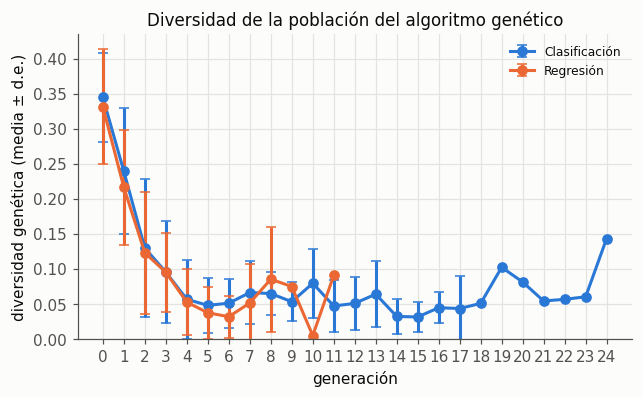

,tarea,generation,diversidad,sd,n,evals
0,Clasificación,0,0.345,0.063,140,6.000
1,Clasificación,1,0.239,0.090,140,8.714
2,Clasificación,2,0.130,0.099,140,10.957
3,Clasificación,3,0.096,0.073,140,12.857
4,Clasificación,4,0.057,0.056,104,13.260
5,Clasificación,5,0.048,0.039,73,13.301
6,Clasificación,6,0.051,0.035,49,12.633
7,Clasificación,7,0.066,0.045,44,13.477
8,Clasificación,8,0.065,0.031,37,13.784
9,Clasificación,9,0.053,0.028,30,14.233


In [10]:
gd = pd.concat([A.ga_diversity('clf').assign(tarea='Clasificación'), A.ga_diversity('reg').assign(tarea='Regresión')])
gsum = gd.groupby(['tarea', 'generation']).agg(diversidad=('diversity', 'mean'), sd=('diversity', 'std'),
                                                 n=('diversity', 'size'), evals=('evals', 'mean')).reset_index()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for i, (t, x) in enumerate(gsum.groupby('tarea')):
    ax.errorbar(x.generation, x.diversidad, yerr=x.sd, marker='o', ms=6, capsize=3, color=P.SERIES[i], label=t)
ax.set_xlabel('generación'); ax.set_ylabel('diversidad genética (media ± d.e.)')
ax.set_title('Diversidad de la población del algoritmo genético'); ax.legend(fontsize=8); ax.set_ylim(0, None)
ax.set_xticks(sorted(gsum.generation.unique()))
P.save(fig, 'e3_hpo_ga_diversidad'); plt.show()
gsum.round(3)

**Interpretación.** La diversidad empieza en 0,35 (población aleatoria) y cae rápido: 0,24 en la generación 1, 0,13 en la 2
y 0,10 en la 3, para estabilizarse en torno a 0,05. Es decir, en 3 generaciones la población se concentra
en una región del espacio. Con 6 individuos y elitismo es una convergencia **rápida, casi prematura**, y
explica por qué el genético mejora tan poco después de la evaluación 8 (curva *anytime* casi plana). Las
generaciones posteriores a la 4 aparecen en pocas búsquedas: cuando la población converge, muchos hijos
repiten configuraciones ya evaluadas, que no consumen presupuesto, y la búsqueda necesita más generaciones
para agotar las 16 evaluaciones. Una población mayor o una mutación más fuerte mantendría más diversidad,
pero con 16 evaluaciones sería prácticamente una búsqueda aleatoria; es el compromiso de usar un genético
con poco presupuesto.

## 7.8 Sesgo de selección: puntaje interno frente a externo

El mejor puntaje interno es el máximo de 16 estimaciones ruidosas, así que tiende a ser
optimista. La validación anidada existe para no reportarlo. La diferencia interno − externo mide
cuánto se habría sobreestimado el desempeño.

In [11]:
sb_c = A.selection_bias('clf', 'recall'); sb_r = A.selection_bias('reg', 'rmse')
tab = pd.DataFrame({
    'Clasificación: interno − externo (balanced acc.)': sb_c.groupby('optimizer').optimismo.mean(),
    'Regresión: externo − interno (RMSE)': sb_r.groupby('optimizer').optimismo.mean(),
}).reindex(OPTS)
print('Media global clasificación:', round(sb_c.optimismo.mean(), 4), '| % de celdas con interno > externo:', round((sb_c.optimismo > 0).mean() * 100, 1))
print('Media global regresión:', round(sb_r.optimismo.mean(), 4), '| % de celdas con RMSE externo > interno:', round((sb_r.optimismo > 0).mean() * 100, 1))
tab.round(4)

Media global clasificación: -0.0022 | % de celdas con interno > externo: 58.0
Media global regresión: -0.0012 | % de celdas con RMSE externo > interno: 22.9


,Clasificación: interno − externo (balanced acc.),Regresión: externo − interno (RMSE)
optimizer,,
grid,-0.0019,-0.0013
random,-0.0020,-0.0014
bayes,-0.0036,-0.0007
genetic,-0.0012,-0.0014


**Interpretación.** Sorprende que el optimismo medio sea ligeramente **negativo** (−0,002 en clasificación): el puntaje externo
es, en promedio, algo mejor que el interno. Hay dos efectos opuestos. El sesgo de selección (elegir el
máximo de 16 estimaciones ruidosas) empuja el interno hacia arriba, y por eso en el 58 % de las celdas el
interno supera al externo. Pero el modelo final se reajusta con todo el entrenamiento externo (unas 24.000
filas), un 50 % más de datos que cada entrenamiento interno (unas 16.000), y eso mejora el externo. Con este
presupuesto pequeño y un paisaje plano, el sesgo de selección es pequeño y el efecto del tamaño lo
compensa. La validación anidada no cambia mucho las cifras en este problema, pero es la única forma de
saberlo; la desviación entre pliegues (±0,06 a ±0,10) es mucho mayor que ese optimismo.

## 7.9 Optimización multi-fidelidad: Successive Halving

Se compara, en el pliegue externo 1 y para XGBoost sin balanceo, una búsqueda aleatoria de 27
configuraciones evaluadas con presupuesto completo (400 árboles) contra **Successive Halving**
(`HalvingRandomSearchCV`) con las mismas 27 configuraciones iniciales:

- **Fidelidad = número de árboles.** Es el recurso natural del boosting: los primeros árboles
  ya ordenan bien las configuraciones (un learning rate o una profundidad malos se notan pronto) y
  el costo crece linealmente con él.
- **Factor de reducción η = 3.** En cada ronda sobrevive el mejor tercio y recibe el triple de
  árboles: 27 configuraciones con ~15 árboles → 9 con ~44 → 3 con ~133 → 1 con 400. Con η = 3 hay
  4 rondas, un equilibrio entre descartar demasiado pronto (η grande) y gastar mucho en las malas
  (η pequeño).

In [12]:
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import HalvingRandomSearchCV, RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier
import time
def run_halving():
    X, y, g, s = N.task_data('clf')
    tr, te = N.outer_folds('clf')[0]
    folds = N.inner_folds('clf', tr, 0)
    Xtr, ytr = X.iloc[tr].reset_index(drop=True), y[tr]
    pipe = Pipeline([('onehot', M.make_encoder()),
                     ('model', XGBClassifier(n_estimators=400, tree_method='hist', n_jobs=1, random_state=C.SEED, verbosity=0))])
    dist = {'model__max_depth': randint(2, 11), 'model__learning_rate': loguniform(0.01, 0.3),
            'model__subsample': uniform(0.6, 0.4), 'model__colsample_bytree': uniform(0.4, 0.6),
            'model__min_child_weight': loguniform(1, 20)}
    out = {}
    for name, search in [
        ('Random (27 × 400 árboles)', RandomizedSearchCV(pipe, dist, n_iter=27, cv=folds, scoring='balanced_accuracy',
                                                       random_state=C.SEED, n_jobs=11, refit=True)),
        ('Successive Halving (η = 3)', HalvingRandomSearchCV(pipe, dist, n_candidates=27, factor=3, resource='model__n_estimators',
                                                           min_resources=15, max_resources=400, cv=folds, scoring='balanced_accuracy',
                                                           random_state=C.SEED, n_jobs=11, refit=True))]:
        t0 = time.perf_counter(); search.fit(Xtr, ytr); sec = time.perf_counter() - t0
        res = pd.DataFrame(search.cv_results_)
        trees = res['param_model__n_estimators'].astype(float) if 'param_model__n_estimators' in res else pd.Series(400.0, index=res.index)
        out[name] = {'segundos (reloj, 11 procesos)': sec, 'árboles ajustados (suma × 3 pliegues)': float(trees.sum() * 3),
                     'configuraciones evaluadas': len(res), 'mejor interno': search.best_score_,
                     'balanced acc. externa': S.score_predictions('clf', y[te], search.best_estimator_, X.iloc[te]),
                     'rondas': int(getattr(search, 'n_iterations_', 1))}
    return pd.DataFrame(out).T
halv = cache.cached('hpo_halving', run_halving)
halv

,"segundos (reloj, 11 procesos)",árboles ajustados (suma × 3 pliegues),configuraciones evaluadas,mejor interno,balanced acc. externa,rondas
Random (27 × 400 árboles),95.011718,32400.0,27.0,0.38202,0.362341,1.0
Successive Halving (η = 3),23.890466,3645.0,39.0,0.38289,0.358669,3.0


**Interpretación.** Successive Halving (η = 3) evaluó 39 configuraciones en 3 rondas (27 con 15 árboles, 9 con 45, 3 con 135)
ajustando en total 3.645 árboles, frente a los 32.400 de la búsqueda aleatoria con presupuesto completo:
**8,9 veces menos árboles y 4 veces menos tiempo de reloj** (24 frente a 95 segundos con 11 procesos). Su
mejor puntaje interno fue igual (0,383 frente a 0,382) y la balanced accuracy externa, prácticamente igual
(0,359 frente a 0,362; diferencia menor que la variación entre pliegues). La fidelidad elegida, el número de
árboles, funciona porque las configuraciones malas (learning rate muy bajo, árboles muy poco profundos) ya se
notan con pocos árboles. Con un paisaje tan plano como este, la multi-fidelidad es la mejora de eficiencia
más grande de todo el capítulo.